In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create a Synthetic Dataset (Replace df with your actual DataFrame)
np.random.seed(42)
n_samples = 300

data = {
    'Branch': np.random.choice(['CSE', 'ECE', 'MECH', 'CIVIL'], n_samples),
    'Gender': np.random.choice(['Male', 'Female'], n_samples),
    'Years_Experience': np.random.uniform(0, 3, n_samples),
    'Internships': np.random.randint(0, 4, n_samples),
    'PlacementStatus': np.random.choice([0, 1], n_samples, p=[0.4, 0.6]),
    'CGPA_Tier': np.random.choice(
        ['Tier_1', 'Tier_2', 'Tier_3'], n_samples, p=[0.3, 0.5, 0.2]
    ),
}
df = pd.DataFrame(data)

# Separate features and targets
X = df.drop(columns=['PlacementStatus', 'CGPA_Tier'])
y_binary = df['PlacementStatus']
y_multi = df['CGPA_Tier']

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()
numerical_cols = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

print('Data and columns initialized successfully!')

Data and columns initialized successfully!


In [ ]:
# Define OHE + Scaling Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', drop='first'),
            categorical_cols,
        ),
    ]
)

print('Preprocessor pipeline defined.')

Preprocessor pipeline defined.


In [ ]:
def evaluate_classifier(model, X_test, y_test, model_name='Classifier'):
  """Evaluates model performance with accuracy, classification report, and confusion matrix."""
  print(f'=== {model_name} Evaluation ===')
  y_pred = model.predict(X_test)

  acc = accuracy_score(y_test, y_pred)
  print(f'Accuracy: {acc:.4f}\n')

  print('Classification Report:')
  print(classification_report(y_test, y_pred))

  print('Confusion Matrix:')
  cm = confusion_matrix(y_test, y_pred)
  plt.figure(figsize=(5, 4))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.title(f'{model_name} - Confusion Matrix')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.show()
  print('-' * 50)

=== Binary LR (PlacementStatus) Evaluation ===
Accuracy: 0.5833

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.17      0.24        24
           1       0.61      0.86      0.71        36

    accuracy                           0.58        60
   macro avg       0.53      0.51      0.48        60
weighted avg       0.54      0.58      0.52        60

Confusion Matrix:


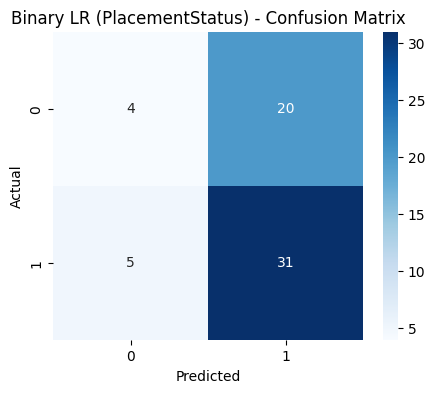

--------------------------------------------------


In [ ]:
# Split data for binary classification
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

# Create and fit binary pipeline
binary_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression())]
)

binary_pipeline.fit(X_train_b, y_train_b)

# Evaluate
evaluate_classifier(
    binary_pipeline, X_test_b, y_test_b, model_name='Binary LR (PlacementStatus)'
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: 

=== Multinomial LR (CGPA_Tier) Evaluation ===
Accuracy: 0.5333

Classification Report:
              precision    recall  f1-score   support

      Tier_1       0.00      0.00      0.00        21
      Tier_2       0.53      1.00      0.70        32
      Tier_3       0.00      0.00      0.00         7

    accuracy                           0.53        60
   macro avg       0.18      0.33      0.23        60
weighted avg       0.28      0.53      0.37        60

Confusion Matrix:


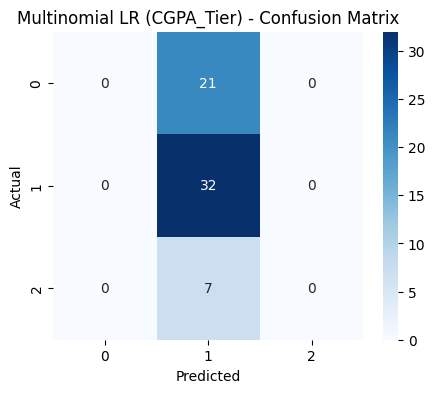

--------------------------------------------------


In [ ]:
# Split data for multinomial classification
X_train_m, X_test_m, y_train_mu, y_test_mu = train_test_split(
    X, y_multi, test_size=0.2, random_state=42
)

# Create and fit multinomial pipeline
multi_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            LogisticRegression(multi_class='multinomial', max_iter=500),
        ),
    ]
)

multi_pipeline.fit(X_train_m, y_train_mu)

# Evaluate
evaluate_classifier(
    multi_pipeline, X_test_m, y_test_mu, model_name='Multinomial LR (CGPA_Tier)'
)

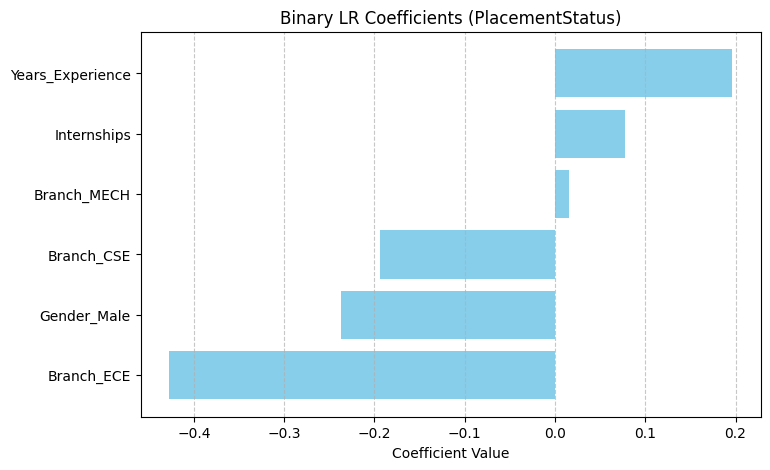

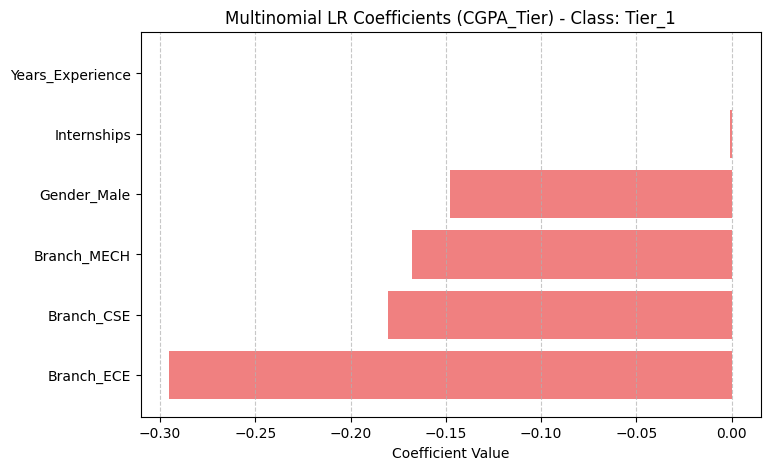

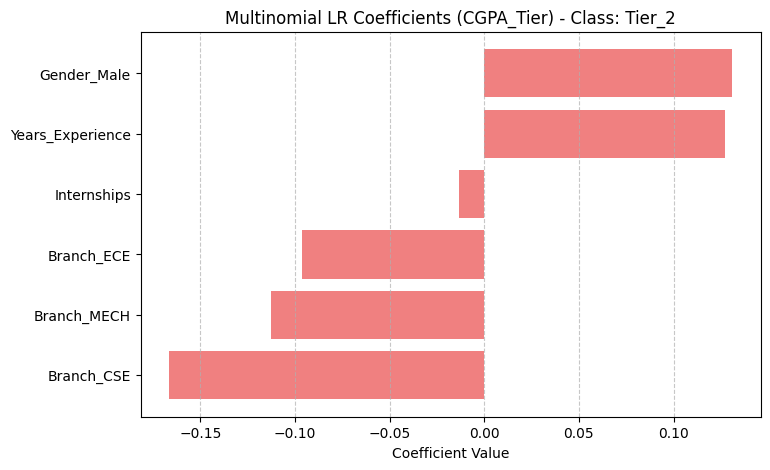

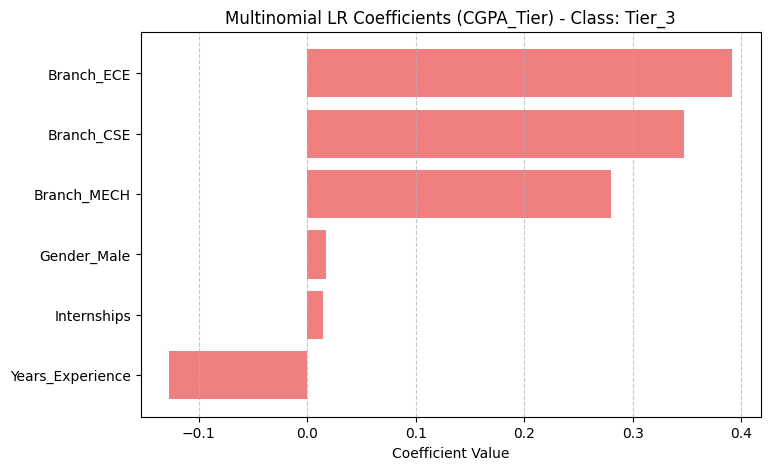

In [ ]:
def plot_coefficients(pipeline, title="Feature Coefficients"):
  """Extracts and plots feature coefficients from a fitted pipeline."""
  preproc = pipeline.named_steps["preprocessor"]
  clf = pipeline.named_steps["classifier"]

  # Retrieve feature names after OHE and scaling
  ohe = preproc.named_transformers_["cat"]
  cat_feature_names = ohe.get_feature_names_out(categorical_cols).tolist()
  all_features = numerical_cols + cat_feature_names

  # Handle binary (shape [1, n_features]) vs multinomial coefficient shapes
  if clf.coef_.ndim == 1 or clf.coef_.shape[0] == 1:
    coefs = clf.coef_[0] if clf.coef_.ndim == 2 else clf.coef_
    coef_df = pd.DataFrame({"Feature": all_features, "Coefficient": coefs})
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)

    plt.figure(figsize=(8, 5))
    plt.barh(coef_df["Feature"], coef_df["Coefficient"], color="skyblue")
    plt.title(title)
    plt.xlabel("Coefficient Value")
    plt.grid(axis="x", linestyle="--", alpha=0.7)
    plt.show()
  else:
    for i, class_name in enumerate(clf.classes_):
      coefs = clf.coef_[i]
      coef_df = pd.DataFrame({"Feature": all_features, "Coefficient": coefs})
      coef_df = coef_df.sort_values(by="Coefficient", ascending=True)

      plt.figure(figsize=(8, 5))
      plt.barh(coef_df["Feature"], coef_df["Coefficient"], color="lightcoral")
      plt.title(f"{title} - Class: {class_name}")
      plt.xlabel("Coefficient Value")
      plt.grid(axis="x", linestyle="--", alpha=0.7)
      plt.show()


# Generate plots
plot_coefficients(
    binary_pipeline, title="Binary LR Coefficients (PlacementStatus)"
)
plot_coefficients(multi_pipeline, title="Multinomial LR Coefficients (CGPA_Tier)")

Write evaluate_classifier(model, X_train, y_train, X_val, y_val) — fits and prints train accuracy, val accuracy, classification_report for 3
models

In [ ]:
from sklearn.metrics import accuracy_score, classification_report


def evaluate_classifier(model, X_train, y_train, X_val, y_val):
  """Fits the model, calculates train/val accuracy, and prints the validation classification report."""
  # 1. Fit the model on training data
  model.fit(X_train, y_train)

  # 2. Predict on train and validation sets
  y_train_pred = model.predict(X_train)
  y_val_pred = model.predict(X_val)

  # 3. Calculate accuracies
  train_acc = accuracy_score(y_train, y_train_pred)
  val_acc = accuracy_score(y_val, y_val_pred)

  # 4. Print metrics
  model_name = type(model.named_steps['classifier']).__name__
  print(f'================ {model_name} Model Evaluation ================')
  print(f'Training Accuracy   : {train_acc:.4f}')
  print(f'Validation Accuracy : {val_acc:.4f}\n')

  print('Validation Classification Report:')
  print(classification_report(y_val, y_val_pred))
  print('=' * 63 + '\n')

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Split your data into Train and Validation (using binary PlacementStatus as an example)
X_train, X_val, y_train, y_val = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

# Define the 3 models using your preprocessor pipeline
models = [
    Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', LogisticRegression(max_iter=500)),
        ]
    ),
    Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', RandomForestClassifier(random_state=42)),
        ]
    ),
    Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', SVC(random_state=42)),
        ]
    ),
]

# Evaluate all 3 models using the function
for model in models:
  evaluate_classifier(model, X_train, y_train, X_val, y_val)

================ LogisticRegression Model Evaluation ================
Training Accuracy   : 0.6000
Validation Accuracy : 0.5833

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.17      0.24        24
           1       0.61      0.86      0.71        36

    accuracy                           0.58        60
   macro avg       0.53      0.51      0.48        60
weighted avg       0.54      0.58      0.52        60


================ RandomForestClassifier Model Evaluation ================
Training Accuracy   : 1.0000
Validation Accuracy : 0.5333

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.42      0.42        24
           1       0.61      0.61      0.61        36

    accuracy                           0.53        60
   macro avg       0.51      0.51      0.51        60
weighted avg       0.53      0.53      0.53        60


==============